Two-feature linear dataset:
$$
y = 3x_1 - 2x_2 + 4 + \epsilon
$$
where:
- $x_1,x_2 \sim \mathcal{N}(0,1)$
- $\epsilon \sim \mathcal{N}(0,0.2^2)$
- Number of samples: 200
- Random seed: 47
- Training/test split: 160/40

In [1]:
import numpy as np
rng = np.random.default_rng(seed=47)

n = 200
X = rng.normal(0, 1, size=(n, 2))

true_w = np.array([3.0, -2.0])
true_b = 4.0
noise = rng.normal(0, 0.2, size=n)

y = X @ true_w + true_b + noise

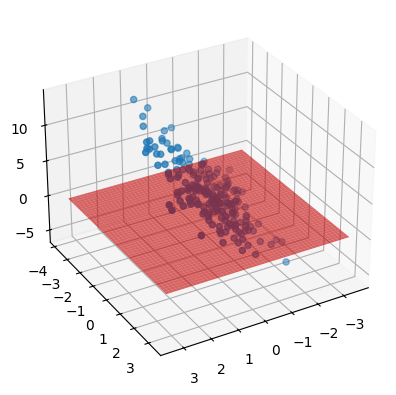

In [27]:
import matplotlib.pyplot as plt

def plot(w, b):
    fig = plt.figure()
    ax = plt.axes(projection='3d')
    ax.view_init(elev=30, azim=60, roll=0)

    ax.scatter(X[:, 0], X[:, 1], y)

    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    
    x1_grid, x2_grid = np.meshgrid(np.linspace(x1_min, x1_max, 50), 
                                   np.linspace(x2_min, x2_max, 50))

    grid_points = np.c_[x1_grid.ravel(), x2_grid.ravel()]
    Z = (grid_points @ w + b).reshape(x1_grid.shape)

    surface = ax.plot_surface(x1_grid, x2_grid, Z, color='red', alpha=0.6, edgecolor='none')

    plt.show()

plot(np.array([0.0, 0.0]), 0.0)

(Batch) Gradient Descent

Epoch: 0
MSE Loss: 27.33938333470427
---
Epoch: 1
MSE Loss: 22.422186888754567
---
Epoch: 2
MSE Loss: 18.39298047406213
---
Epoch: 3
MSE Loss: 15.090945060994077
---
Epoch: 4
MSE Loss: 12.384469743839606
---
Epoch: 5
MSE Loss: 10.16583190918349
---
Epoch: 6
MSE Loss: 8.346849042279322
---
Epoch: 7
MSE Loss: 6.855324220000762
---
Epoch: 8
MSE Loss: 5.632140017355381
---
Epoch: 9
MSE Loss: 4.628882216375573
---
Epoch: 10
MSE Loss: 3.8058964619815527
---
Epoch: 11
MSE Loss: 3.130698764195553
---
Epoch: 12
MSE Loss: 2.5766752375574824
---
Epoch: 13
MSE Loss: 2.122018298089072
---
Epoch: 14
MSE Loss: 1.7488561959288103
---
Epoch: 15
MSE Loss: 1.4425406475512705
---
Epoch: 16
MSE Loss: 1.1910637712657937
---
Epoch: 17
MSE Loss: 0.9845807893161791
---
Epoch: 18
MSE Loss: 0.815019256226256
---
Epoch: 19
MSE Loss: 0.675759082958233
---
Epoch: 20
MSE Loss: 0.5613704943027216
---
Epoch: 21
MSE Loss: 0.46739940047338385
---
Epoch: 22
MSE Loss: 0.390191579247994
---
Epoch: 23
MSE Loss: 0.3267486306

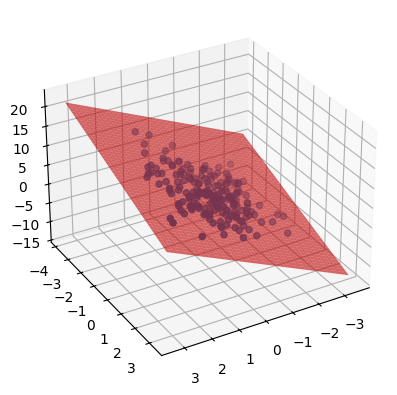

In [ ]:
gd_lr = 0.05
gd_w = np.array([0.0, 0.0])
gd_b = 0.0

for epoch in range(500):
    gd_y = X @ gd_w + gd_b

    gd_gradient_w = (2*(gd_y - y).reshape(1,-1) @ X).reshape(-1)/n
    gd_gradient_b = (2*(gd_y - y)).mean()

    gd_w -= gd_gradient_w*gd_lr 
    gd_b -= gd_gradient_b*gd_lr

    gd_loss = ((gd_y - y)**2).mean()

    print(f"Epoch: {epoch}")
    print(f"MSE Loss: {gd_loss}")
    print("---")

print(gd_w, gd_b)
plot(gd_w, gd_b)
        

Stochastic Gradient Descent

epoch: 0
i: 0
MSE Loss: 27.276135983857056
---
epoch: 0
i: 1
MSE Loss: 27.203267933852675
---
epoch: 0
i: 2
MSE Loss: 27.170242761375757
---
epoch: 0
i: 3
MSE Loss: 27.035745230923382
---
epoch: 0
i: 4
MSE Loss: 26.53334655204274
---
epoch: 0
i: 5
MSE Loss: 26.37834980808414
---
epoch: 0
i: 6
MSE Loss: 26.17966262554161
---
epoch: 0
i: 7
MSE Loss: 24.080606119454504
---
epoch: 0
i: 8
MSE Loss: 22.13593850450741
---
epoch: 0
i: 9
MSE Loss: 22.071963718549778
---
epoch: 0
i: 10
MSE Loss: 21.34622091313071
---
epoch: 0
i: 11
MSE Loss: 21.174544776072224
---
epoch: 0
i: 12
MSE Loss: 21.03612722990762
---
epoch: 0
i: 13
MSE Loss: 20.652385201494646
---
epoch: 0
i: 14
MSE Loss: 20.25862969462942
---
epoch: 0
i: 15
MSE Loss: 19.571560377366318
---
epoch: 0
i: 16
MSE Loss: 19.429974321478667
---
epoch: 0
i: 17
MSE Loss: 19.36034049517346
---
epoch: 0
i: 18
MSE Loss: 19.35752666007366
---
epoch: 0
i: 19
MSE Loss: 18.541824388283313
---
epoch: 0
i: 20
MSE Loss: 18.112536536254414
---
epoch: 0
i:

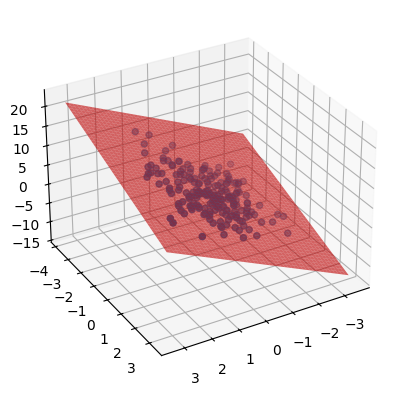

In [42]:
gd_lr = 0.005
gd_w = np.array([0.0, 0.0])
gd_b = 0.0

for epoch in range(200):
    for i in range(n):
        gd_y = X[i] @ gd_w.reshape(-1, 1) + gd_b
        gd_gradient_w = (2*(gd_y - y[i])*X[i]).reshape(-1)
        gd_gradient_b = 2*(gd_y - y[i])

        gd_w -= gd_gradient_w*gd_lr 
        gd_b -= gd_gradient_b*gd_lr

        gd_loss = ((X @ gd_w + gd_b - y)**2).mean()

        print(f"epoch: {epoch}")
        print(f"i: {i}")
        print(f"MSE Loss: {gd_loss}")
        print("---")

print(gd_w, gd_b)
plot(gd_w, gd_b)
        